In [48]:
import openmc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import structural_material_analysis as sma
from openmc_model import reactor_model, available_materials

## Geometry

Please enter the name of the material!

In [49]:
# Make a choice of material for the vacuum vessel
# Options: inconel718, ss316l, silicon_carbide, vcrti, ods_eurofer, ht9

material_name = "silicon_carbide"

In [50]:
str_material = available_materials[material_name]
model, root = reactor_model(str_material)
geometry = model.geometry

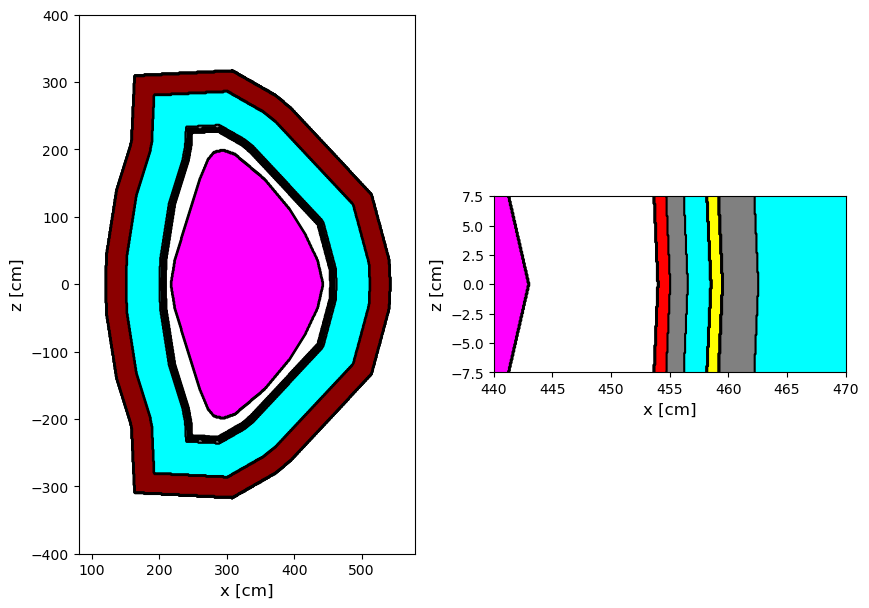

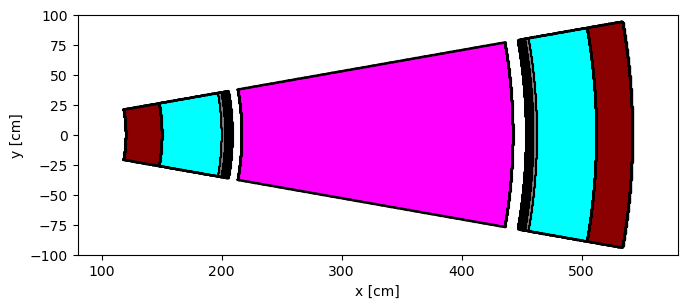

In [51]:
colors={root[0]:'magenta', root[1]:'white', root[2]:'red', root[3]:'grey', root[4]:'aqua', 
        root[5]:'yellow', root[6]:'grey', root[7]:'aqua', root[8]:'darkred', root[9]:'white'}

label_style = {
    'fontsize': 12,
    'fontweight': 'normal', #bold
    # 'family': 'Serif',
    'style': 'normal' #italic
}

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10,7))
geometry.plot(origin=(330, 0, 0), basis='xz', width=[500, 800], pixels=[600, 600], axes=ax1, 
              color_by='cell', colors=colors, outline=True)
ax1.set_xlabel('x [cm]', **label_style)
ax1.set_ylabel('z [cm]', **label_style)
geometry.plot(origin=(455, 0, 0), basis='xz', width=[30, 15], pixels=[400, 400], axes=ax2, 
              color_by='cell', colors=colors, outline=True)
ax2.set_xlabel('x [cm]', **label_style)
ax2.set_ylabel('z [cm]', **label_style)
plt.show()

geometry.plot(origin=(330, 0, 0), basis='xy', width=[500, 200], pixels=[600, 600], 
              color_by='cell', colors=colors, outline=True)
plt.show()

## Results
- TBR
- Neutron spectra
- Heating
- EM
- NRT-DPA

In [52]:
fusion_power = 525e6  # units Watts
energy_per_fusion_reaction = 17.6e6  # units eV
eV_to_Joules = 1.60218e-19  # multiplication factor to convert eV to Joules
number_of_neutrons_per_second = fusion_power / (energy_per_fusion_reaction * eV_to_Joules)
print('Number of neutrons per second', number_of_neutrons_per_second, '\n')

fw_volume = 2234489.71 # units cm^3
fw_surface = 4468977.87 # units cm^2
vessel_inner_volume = 3376578.27 # units cm^3
vessel_inner_surface = 4502100.88 # units cm^2
cooling_channel_volume = 4548430.53 # units cm^3
cooling_channel_surface = 4548424.34 # units cm^2
multiplier_volume = 2294048.43 # units cm^3
multiplier_surface = 4588095.32 # units cm^2
vessel_outer_volume = 6961366.51 # units cm^3
vessel_outer_surface = 4640897.08 # units cm^2
blanket_volume = 133295915.93 # units cm^3
blanket_surface = 5327966.21 # units cm^2
shielding_volume = 95312753.08 # units cm^3
shielding_surface = 6352790.18 # units cm^2

Number of neutrons per second 1.8618098749544654e+20 



In [53]:
sp = openmc.StatePoint(f"results/{material_name}.h5")

### TBR

In [54]:
tbr_total = sma.analysis.extract_tbr_contributions(sp, "TBR")
tbr_cc = sma.analysis.extract_tbr_contributions(sp, "TBR channel")
tbr_blanket = sma.analysis.extract_tbr_contributions(sp, "TBR blanket")

df = pd.DataFrame([tbr_total, tbr_cc, tbr_blanket], index=["Total", "Channel", "Blanket"])
print(df)

              TBR  TBR std. dev.       Li6       Li7
Total    0.997392       0.001282  0.908167  0.089226
Channel  0.117492       0.000256  0.100565  0.016927
Blanket  0.879900       0.001219  0.807602  0.072298


In [55]:
rows = []

rows.append([
    material_name,
    tbr_total["TBR"],
    tbr_cc["Li6"], tbr_cc["Li7"],
    tbr_blanket["Li6"], tbr_blanket["Li7"]
])

df = pd.DataFrame(rows, columns=[
    "Material",
    "TBR Total",
    "TBR Channel (Li6)", "TBR Channel (Li7)",
    "TBR Blanket (Li6)", "TBR Blanket (Li7)"
])

print(df.round(5))

          Material  TBR Total  TBR Channel (Li6)  TBR Channel (Li7)  \
0  silicon_carbide    0.99739            0.10056            0.01693   

   TBR Blanket (Li6)  TBR Blanket (Li7)  
0             0.8076             0.0723  


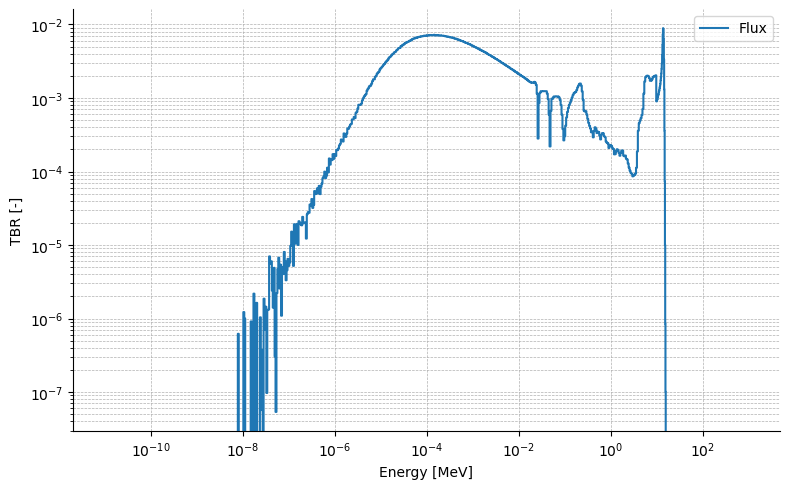

In [56]:
tbr_energy = sp.get_tally(name="TBR(energy)")
df_tbr_energy = tbr_energy.get_pandas_dataframe()
tbr_energy_val = df_tbr_energy['mean'].values

energy_bins = openmc.mgxs.GROUP_STRUCTURES["CCFE-709"]
energy_filter = openmc.EnergyFilter(energy_bins)

plt.figure(figsize=(8, 5))
plt.step(energy_filter.values[:-1] / 1e6, tbr_energy_val, where='mid', label='Flux')
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Energy [MeV]")
plt.ylabel('TBR [-]')
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

In [57]:
sum(tbr_energy_val)

np.float64(1.0059799261193167)

### Neutron Spectra

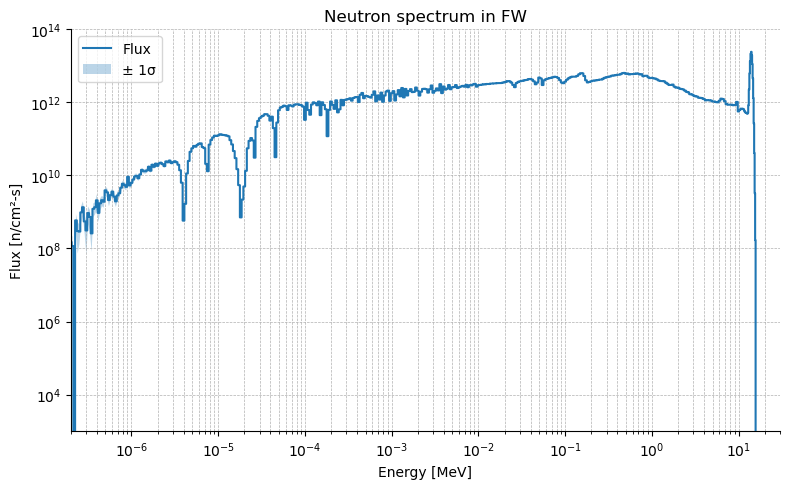

Mean neutron flux in FW: 8.53e+14 ± 8.45e+12 n/cm²-s


In [58]:
ns_tally_fw = sp.get_tally(name="neutron_spectra_fw")

sma.analysis.plot_neutron_spectrum(ns_tally_fw, "FW", fw_volume, number_of_neutrons_per_second)

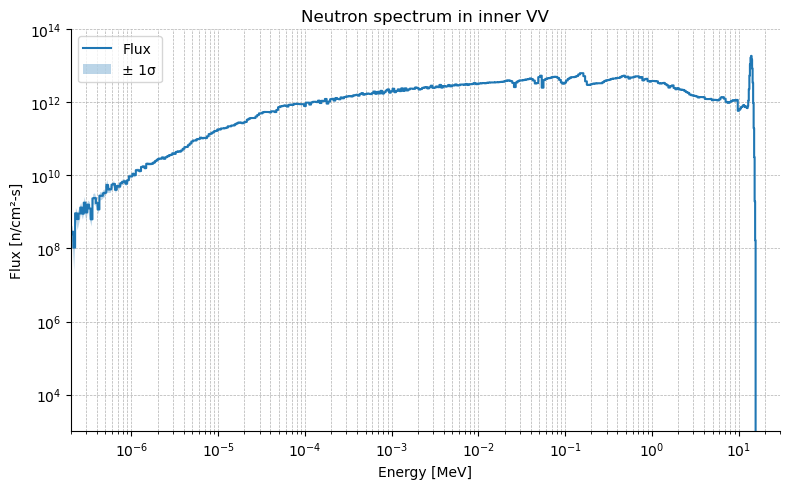

Mean neutron flux in inner VV: 8.40e+14 ± 6.86e+12 n/cm²-s


In [59]:
ns_tally_str1 = sp.get_tally(name="neutron_spectra_str1")

sma.analysis.plot_neutron_spectrum(ns_tally_str1, 'inner VV', vessel_inner_volume, number_of_neutrons_per_second)

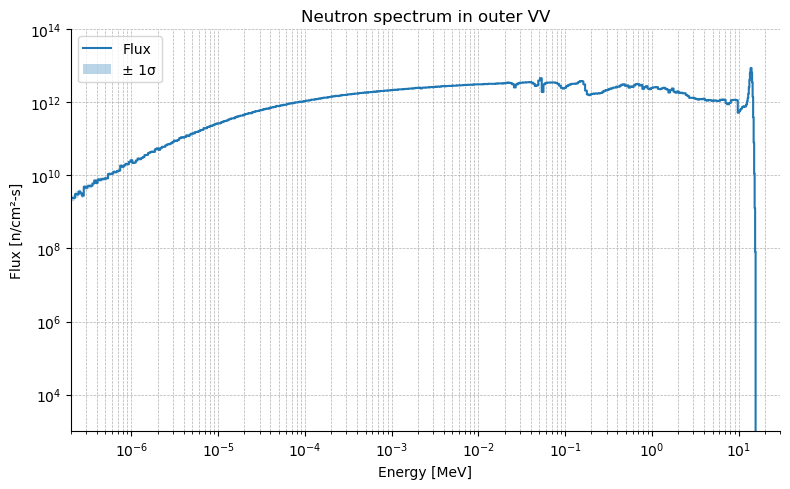

Mean neutron flux in outer VV: 6.79e+14 ± 4.99e+12 n/cm²-s


In [60]:
ns_tally_str2 = sp.get_tally(name="neutron_spectra_str2")

sma.analysis.plot_neutron_spectrum(ns_tally_str2, 'outer VV', vessel_outer_volume, number_of_neutrons_per_second)

### Power density

   Particle  Power [MW]  Power Density [MW/m³]
0         N    2.708075               1.211943
1  Electron   60.359221              27.012530
2  Positron    0.850071               0.380432
3    Photon    4.721685               2.113093
4     Total   68.639052              30.717999


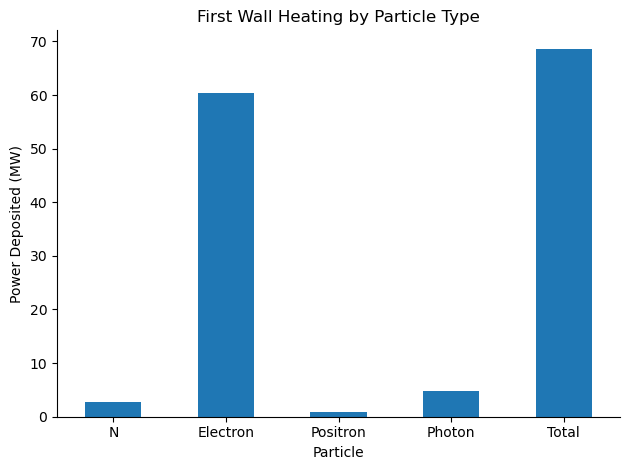

In [61]:
df = sma.analysis.compute_region_heating(sp, 'heating_fw', number_of_neutrons_per_second, fw_volume)
print(df)

df.plot(kind='bar', y='Power [MW]', x='Particle', legend=False)
plt.ylabel('Power Deposited (MW)')
plt.title('First Wall Heating by Particle Type')
plt.xticks(rotation=0)
plt.tight_layout()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

   Particle  Power [MW]  Power Density [MW/m³]
0         N   20.984575               6.214746
1  Electron   10.703142               3.169819
2  Positron    0.157916               0.046768
3    Photon    0.214674               0.063577
4     Total   32.060307               9.494910


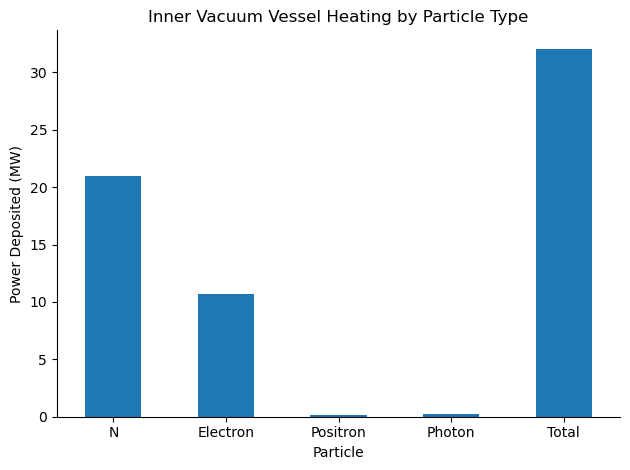

In [62]:
df = sma.analysis.compute_region_heating(sp, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
print(df)

df.plot(kind='bar', y='Power [MW]', x='Particle', legend=False)
plt.ylabel('Power Deposited (MW)')
plt.title('Inner Vacuum Vessel Heating by Particle Type')
plt.xticks(rotation=0)
plt.tight_layout()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

   Particle  Power [MW]  Power Density [MW/m³]
0         N   26.774743               3.846191
1  Electron   17.030427               2.446420
2  Positron    0.286523               0.041159
3    Photon    0.344132               0.049435
4     Total   44.435825               6.383204


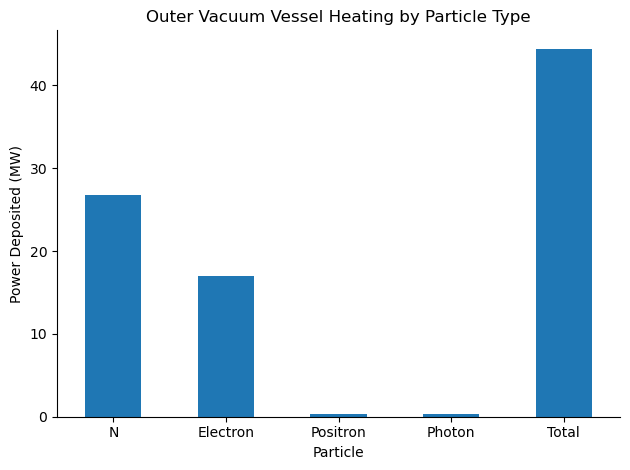

In [63]:
df = sma.analysis.compute_region_heating(sp, 'heating_str2', number_of_neutrons_per_second, vessel_outer_volume)
print(df)

df.plot(kind='bar', y='Power [MW]', x='Particle', legend=False)
plt.ylabel('Power Deposited (MW)')
plt.title('Outer Vacuum Vessel Heating by Particle Type')
plt.xticks(rotation=0)
plt.tight_layout()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

### Energy Multiplication EM

In [64]:
E_source = 14.1  
cc_tally = sp.get_tally(name='heating_cc')
blanket_tally = sp.get_tally(name='heating_blanket')
nm_tally = sp.get_tally(name='heating_nm')
em_ms_value = (cc_tally.mean.sum() + blanket_tally.mean.sum() + nm_tally.mean.sum()) / 1e6 / E_source
print(f"Energy Multiplication (EM) on molten salt: {em_ms_value:.3f}")


Energy Multiplication (EM) on molten salt: 0.769


In [65]:
full_tally = sp.get_tally(name='heating_full')
em = full_tally.mean.sum() / 1e6 / E_source
print(f"Energy Multiplication (EM): {em:.4f}")


Energy Multiplication (EM): 1.1338


### Displacement Per Atoms DPA

The **damage-energy** ($T_{d}$) represents the kinetic energy available for creating atomic displacements. This variable can be used to compute the total number of displacements per atom (DPA). 

The current international standard [^1] for quantifying DPA is based on the **Kinchin-Pease model** or **NRT equation** [^2], which states that the number of Frenkel pairs produced ($N_{d}$) in a material with displacement energy $E_{d}$ for a nuclear deposited energy $T_{d}$ is:

$$
N_{d} = \dfrac{0.8T_{d}}{2E_d}
$$

where the factor 0.8 was introduced by the authors to allow for realistic atomic scattering instead of the hard core approximation.

[^1]: ASTM Standard E693-94, *Standard practice for characterising neutron exposure in iron and low alloy steels in terms of displacements per atom (DPA)*, 1994  
[^2]: [NRT paper](https://doi.org/10.1016%2F0029-5493%2875%2990035-7)


In [66]:
dpa_tally_str1 = sp.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()

props = sma.materials.properties.structural[material_name]

result = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,  
    atomic_mass_u=props["mass_u"],                
    density_g_per_cm3=str_material.density,  
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],  
)
print(f"DPA = {result['DPA']}")

DPA = 17.450999877319145


In [67]:
dpa_tally_str2 = sp.get_tally(name="dpa_str2")
df_str2 = dpa_tally_str2.get_pandas_dataframe()

props = sma.materials.properties.structural[material_name]

result = sma.analysis.compute_dpa_from_tally(
    df=df_str2,
    number_of_neutrons_per_second=number_of_neutrons_per_second,  
    atomic_mass_u=props["mass_u"],                
    density_g_per_cm3=str_material.density,  
    volume_cm3=vessel_outer_volume,
    Ed_eV=props["Ed"],  
)
print(f"DPA = {result['DPA']}")

DPA = 11.511495738655137


### Absorption Rate

In [68]:
abs_tally_str1 = sp.get_tally(name="absorption_str1")
df_str1 = abs_tally_str1.get_pandas_dataframe()
print(f"Absorption rate on inner vacuum vessel: {df_str1['mean'].mean():.4f} [events/source neutron]")

abs_tally_str2 = sp.get_tally(name="absorption_str2")
df_str2 = abs_tally_str2.get_pandas_dataframe()
print(f"Absorption rate on outer vacuum vessel: {df_str2['mean'].mean():.4f} [events/source neutron]")


Absorption rate on inner vacuum vessel: 0.0500 [events/source neutron]
Absorption rate on outer vacuum vessel: 0.0663 [events/source neutron]


### H & He Production

In [69]:
h1_tally_str1 = sp.get_tally(name="H1-production_str1")
df_h1_str1 = h1_tally_str1.get_pandas_dataframe()

h2_tally_str1 = sp.get_tally(name="H2-production_str1")
df_h2_str1 = h2_tally_str1.get_pandas_dataframe()

h3_tally_str1 = sp.get_tally(name="H3-production_str1")
df_h3_str1 = h3_tally_str1.get_pandas_dataframe()

he3_tally_str1 = sp.get_tally(name="He3-production_str1")
df_he3_str1 = he3_tally_str1.get_pandas_dataframe()

he4_tally_str1 = sp.get_tally(name="He4-production_str1")
df_he4_str1 = he4_tally_str1.get_pandas_dataframe()

h_total = df_h1_str1['mean'].mean() + df_h2_str1['mean'].mean() + df_h3_str1['mean'].mean()
he_total = df_he3_str1['mean'].mean() + df_he4_str1['mean'].mean()
df_prod = pd.DataFrame(
    [df_h1_str1['mean'].mean(), df_h2_str1['mean'].mean(), df_h3_str1['mean'].mean(), h_total, df_he3_str1['mean'].mean(), df_he4_str1['mean'].mean(), he_total],
    index=["H1", "H2", "H3", "H total", "He3", "He4", "He total"],
    columns=["Production Rate [atoms/source neutron]"]
)

print(df_prod)

          Production Rate [atoms/source neutron]
H1                                      0.029913
H2                                      0.001312
H3                                      0.000000
H total                                 0.031225
He3                                     0.000000
He4                                     0.072839
He total                                0.072839
